# Fake News Detection on IFND
## Student 4: Fine-Tuned BERT
**Approach:** transformer-based deep learning. **Expected outcome:** a transformer-based fake news classifier.

Choose **Runtime > Change runtime type > T4 GPU**, then **Runtime > Run all**. Expect roughly 15 to 30 minutes on a GPU; on a CPU this notebook is impractically slow.

In [1]:
import copy
import numpy as np
try:
    import transformers
except ImportError:
    %pip install -q transformers
    import transformers
import torch
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Transformers', transformers.__version__, '| device:', device)
if device.type == 'cpu':
    print('WARNING: no GPU found. Switch the runtime to T4 GPU before training.')

Transformers 5.22.0 | device: cuda


## 1. Load IFND and create the shared partitions
This cell downloads IFND from the authors' repository and creates the 70/15/15 train, validation and test partitions shared by all four students. It stops with an error if the file or partitions differ.

Cleaning applied before partitioning: repair broken text encoding, remove headlines shorter than three words, remove headlines that appear with both labels, and keep one copy of each repeated headline.

Only the headline (`Statement`) is used as input. `Web` and `Category` almost reveal the label directly (for example, every `MISLEADING` row is fake), so using them would inflate the results.

In [2]:
# SHARED CELL - keep identical in all four notebooks so the partitions stay identical.
import hashlib, os, re, urllib.request
import pandas as pd

DATA_URL = ('https://raw.githubusercontent.com/sonalgarg174/Dataset/'
            'f47d8407595c288d2a9c4f0f74a5e721a11995b8/IFND.csv')  # authors' repo, pinned commit
DATA_PATH = 'IFND.csv'
FILE_SHA256 = '3728c7b785ea93c9dadcc61a4c549c0eddd71a5fb6a1a31be08b5235ee4f5bfa'
SPLIT_FINGERPRINT = 'd17a2299ad1e64b524d50ac41e3b9828308b4c483a80ced900d85fc913777544'

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
with open(DATA_PATH, 'rb') as f:
    assert hashlib.sha256(f.read()).hexdigest() == FILE_SHA256, 'IFND.csv differs from the agreed file'

raw = pd.read_csv(DATA_PATH, encoding='latin-1', dtype=str, keep_default_na=False)

# The file mixes several broken encodings. Restore apostrophes and drop the remaining debris,
# otherwise a model can learn the scraper's encoding instead of the news content.
APOSTROPHES = ['\x92', '\xd5', '\x89\xdb\xaa', '\xe2\x80\x99', '\xef\xbf\xbd']

def repair_text(text):
    for broken in APOSTROPHES:
        text = text.replace(broken, "'")
    text = re.sub(r'[^\x00-\x7f]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df = pd.DataFrame({
    'id': raw['id'],
    'text': raw['Statement'].map(repair_text),
    'label': raw['Label'].str.strip().str.lower().map({'fake': 1, 'true': 0}),  # Fake = 1, Real = 0
    'source': raw['Web'].str.strip().str.upper(),
})
df['key'] = df['text'].str.lower().str.replace(r'[^a-z0-9]+', ' ', regex=True).str.strip()

rows_loaded = len(df)
df = df[df['key'].str.split().str.len() >= 3]                      # too short to classify
df = df[df.groupby('key')['label'].transform('nunique') == 1]      # same headline, both labels
df = df.drop_duplicates('key').copy()                              # a repeat must not span partitions

# Partition: sort each class by a hash of the headline, then cut 70/15/15. This is a reproducible
# stratified shuffle that does not depend on the installed numpy or scikit-learn version.
df['hash'] = df['key'].map(lambda k: hashlib.sha256(k.encode()).hexdigest())
df = df.sort_values('hash').reset_index(drop=True)
rank = df.groupby('label').cumcount()
size = df.groupby('label')['label'].transform('size')
df['split'] = 'test'
df.loc[rank < (size * 0.85).astype(int), 'split'] = 'val'
df.loc[rank < (size * 0.70).astype(int), 'split'] = 'train'

# Flags used only for the robustness check at the end, never as model inputs.
GIVEAWAY = (r'\b(fact check|factcheck|fake|false|falsely|viral|claim|claims|claimed|misleading|hoax|'
            r'rumou?r|debunk|no this|not a|shared as|shared with|morphed|doctored|old video|old photo|'
            r'video|photo|image|picture)\b')
df['is_augmented'] = df['source'].eq('AUGMENT')
df['has_giveaway'] = df['key'].str.contains(GIVEAWAY.replace('(', '(?:'), regex=True)

fingerprint = hashlib.sha256('\n'.join(df['hash'] + df['split']).encode()).hexdigest()
if SPLIT_FINGERPRINT.startswith('__'):
    print('Fingerprint not pinned yet')
else:
    assert fingerprint == SPLIT_FINGERPRINT, 'Partitions differ from the agreed partitions'

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Rows loaded {rows_loaded:,} | usable after cleaning {len(df):,}')
print('Partition fingerprint:', fingerprint[:16])
print(df.groupby('split')['label'].agg(rows='size', fake='sum', fake_share='mean').round(3))

Rows loaded 56,714 | usable after cleaning 47,892
Partition fingerprint: d17a2299ad1e64b5
        rows   fake  fake_share
split                          
test    7185   2350       0.327
train  33523  10964       0.327
val     7184   2350       0.327


## 2. Shared evaluation
Accuracy, precision, recall and F1 are computed the same way in every notebook. **Fake is the positive class**, so recall means the share of fake headlines that were caught. (The dataset's README describes 1 as true news, while the CSV itself uses `TRUE` and `Fake`; this project sets Fake = 1.)

In [3]:
# SHARED CELL - the same evaluation for all four approaches.
import json
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)

def compute_metrics(y_true, y_pred):
    """Precision, recall and F1 treat Fake (1) as the positive class."""
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0)}

def evaluate_on_test(y_pred, title):
    y_true = test_df['label'].values
    print(classification_report(y_true, y_pred, target_names=['Real', 'Fake'], digits=4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['Real', 'Fake'],
                                            cmap='Blues', values_format=',d')
    plt.title(title)
    plt.show()
    return compute_metrics(y_true, y_pred)

def robustness_check(y_pred):
    """Same predictions, scored on harder parts of the test partition."""
    subsets = {'All test headlines': pd.Series(True, index=test_df.index),
               'Excluding synthetic (AUGMENT)': ~test_df['is_augmented'],
               'Without giveaway words': ~test_df['has_giveaway'],
               'Neither synthetic nor giveaway': ~test_df['is_augmented'] & ~test_df['has_giveaway']}
    rows = []
    for name, mask in subsets.items():
        scores = compute_metrics(test_df.loc[mask, 'label'], y_pred[mask.values])
        rows.append({'subset': name, 'rows': int(mask.sum()),
                     'fake_rows': int(test_df.loc[mask, 'label'].sum()), **scores})
    return pd.DataFrame(rows).set_index('subset').round(4)

def save_results(student, algorithm, y_pred, test_metrics, robustness, details):
    os.makedirs('results', exist_ok=True)
    report = {'student': student, 'algorithm': algorithm, 'partition_fingerprint': fingerprint,
              'test_metrics': test_metrics, 'robustness': robustness.reset_index().to_dict('records'),
              'details': details}
    with open(f'results/student_{student}_metrics.json', 'w') as f:
        json.dump(report, f, indent=2, default=str)
    pd.DataFrame({'id': test_df['id'], 'label': test_df['label'], 'prediction': y_pred}).to_csv(
        f'results/student_{student}_test_predictions.csv', index=False)
    print('Saved to the results folder')

## 3. Tokenize with the BERT tokenizer
BERT needs natural text, so there is no stopword removal or lemmatization beyond the shared encoding repair. The tokenizer adds the `[CLS]` and `[SEP]` tokens and returns input IDs and an attention mask. Headlines are short, so 64 tokens is enough.

In [4]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_NAME = 'bert-base-uncased'
MAX_LEN = 64
BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 2e-5

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_loader(frame, shuffle=False):
    enc = tokenizer(frame['text'].tolist(), truncation=True, padding='max_length',
                    max_length=MAX_LEN, return_tensors='pt')
    labels = torch.tensor(frame['label'].values, dtype=torch.long)
    data = TensorDataset(enc['input_ids'], enc['attention_mask'], labels)
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED))

train_loader = make_loader(train_df, shuffle=True)
val_loader = make_loader(val_df)
test_loader = make_loader(test_df)

print('Tokens:', tokenizer.tokenize(train_df['text'][0])[:20])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokens: ['what', 'happened', 'in', 'the', 'dark', 'of', 'friday', 'night', 'as', 'bjp', 'pulled', 'off', 'a', 'coup', 'in', 'maharashtra', ':', 'a', 'timeline']


## 4. Load pretrained BERT
This loads the pretrained encoder and adds a new two-class classification layer. A warning that some weights were newly initialized is expected, because that new layer has not been trained yet.

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 109,483,778


## 5. Fine-tune
All BERT layers are updated at a small learning rate. The loss uses class weights to offset the smaller number of fake headlines. After each epoch the model is scored on the validation partition, and the weights with the best validation F1 are kept.

In [6]:
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup

counts = np.bincount(train_df['label'].values)
weights = torch.tensor(len(train_df) / (2 * counts), dtype=torch.float, device=device)
loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def predict(loader):
    model.eval()
    probs = []
    with torch.no_grad():
        for input_ids, attention_mask, _ in loader:
            with torch.amp.autocast('cuda', enabled=use_amp):
                logits = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device)).logits
            probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

best_f1, best_state, log = -1, None, []
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for input_ids, attention_mask, labels in tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS}'):
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            logits = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device)).logits
            loss = loss_fn(logits, labels.to(device))
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        running_loss += loss.item()
    val_scores = compute_metrics(val_df['label'].values, (predict(val_loader) >= 0.5).astype(int))
    log.append({'epoch': epoch, 'train_loss': running_loss / len(train_loader), **val_scores})
    print({k: round(v, 4) for k, v in log[-1].items()})
    if val_scores['f1'] > best_f1:
        best_f1 = val_scores['f1']
        best_state = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})

model.load_state_dict(best_state)
print(f'Using the weights with validation F1 = {best_f1:.4f}')

Epoch 1/3:   0%|          | 0/1048 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.1741, 'accuracy': 0.9745, 'precision': 0.9801, 'recall': 0.9413, 'f1': 0.9603}


Epoch 2/3:   0%|          | 0/1048 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.0755, 'accuracy': 0.9793, 'precision': 0.977, 'recall': 0.9591, 'f1': 0.968}


Epoch 3/3:   0%|          | 0/1048 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.0444, 'accuracy': 0.9773, 'precision': 0.9679, 'recall': 0.9626, 'f1': 0.9652}
Using the weights with validation F1 = 0.9680


## 6. Evaluate on the test partition

              precision    recall  f1-score   support

        Real     0.9809    0.9868    0.9838      4835
        Fake     0.9724    0.9604    0.9664      2350

    accuracy                         0.9781      7185
   macro avg     0.9767    0.9736    0.9751      7185
weighted avg     0.9781    0.9781    0.9781      7185



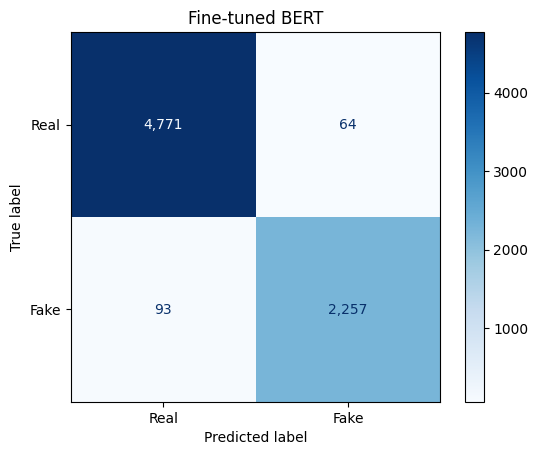

,0
accuracy,0.9781
precision,0.9724
recall,0.9604
f1,0.9664


In [7]:
test_pred = (predict(test_loader) >= 0.5).astype(int)
test_metrics = evaluate_on_test(test_pred, 'Fine-tuned BERT')
pd.Series(test_metrics).round(4)

## Robustness check: how much of the score is real?
Read this table before quoting the headline score. IFND has two known weaknesses:

- **Synthetic rows:** about 60% of the fake rows have the source `AUGMENT`. They were generated from other fake headlines, so a test row can closely resemble a training row.
- **Giveaway words:** fake rows mostly come from fact-checking sites, so their headlines contain words like "fact check" or "viral". Those words identify the publisher's style, not whether a claim is false.

Lower scores in the last rows show how heavily the model relies on these patterns. The word list comes from inspecting the data, so treat this as an indicator rather than a precise measurement.

In [8]:
robustness = robustness_check(test_pred)
robustness

,rows,fake_rows,accuracy,precision,recall,f1
subset,,,,,,
All test headlines,7185,2350,0.9781,0.9724,0.9604,0.9664
Excluding synthetic (AUGMENT),5860,1025,0.9840,0.9396,0.9707,0.9549
Without giveaway words,5193,462,0.9752,0.8955,0.8160,0.8539
Neither synthetic nor giveaway,4922,191,0.9860,0.7905,0.8691,0.8279


## 7. Save results and try a headline
The saved model is about 400 MB, which is too large to commit to GitHub. Download it or copy it to Google Drive if you need to keep it.

In [9]:
save_results(4, 'Fine-tuned BERT', test_pred, test_metrics, robustness,
             {'model_name': MODEL_NAME, 'max_len': MAX_LEN, 'batch_size': BATCH_SIZE,
              'epochs': EPOCHS, 'learning_rate': LEARNING_RATE, 'training_log': log})
model.save_pretrained('models/bert')
tokenizer.save_pretrained('models/bert')

def predict_headline(headline):
    model.eval()
    enc = tokenizer(repair_text(headline), truncation=True, max_length=MAX_LEN, return_tensors='pt').to(device)
    with torch.no_grad():
        prob_fake = torch.softmax(model(**enc).logits, dim=1)[0, 1].item()
    return f"{'FAKE' if prob_fake >= 0.5 else 'REAL'} (probability of fake: {prob_fake:.2f})"

print(predict_headline('Supreme Court seeks response from Centre on new highway plea'))
print(predict_headline('Viral video claims the government will give free phones to all students'))

Saved to the results folder


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

REAL (probability of fake: 0.00)
FAKE (probability of fake: 1.00)


## Upload to GitHub
1. Create the branch `student-4-bert` in the shared repository.
2. In Colab, choose **File > Save a copy in GitHub**, then select the repository and this branch.
3. Add `results/student_4_metrics.json` to the same branch using **Add file > Upload files** on GitHub.

Do not commit `IFND.csv` or saved model files. The dataset's authors allow research use only and ask users to cite: Sharma, D. K., & Garg, S. (2021). *IFND: a benchmark dataset for fake news detection.* Complex & Intelligent Systems.

In [10]:
import shutil
from google.colab import files
import os

# Compress the saved models and results into a single zip file along with the CSV
print("Archiving files...")

# We will copy the IFND.csv into results folder temporarily or just zip them together
os.makedirs('download_package', exist_ok=True)

# Copy IFND.csv to the download package folder if it exists
if os.path.exists('IFND.csv'):
    shutil.copy('IFND.csv', 'download_package/IFND.csv')

# Copy results folder if it exists
if os.path.exists('results'):
    if os.path.exists('download_package/results'):
        shutil.rmtree('download_package/results')
    shutil.copytree('results', 'download_package/results')

# Copy models folder if it exists
if os.path.exists('models'):
    if os.path.exists('download_package/models'):
        shutil.rmtree('download_package/models')
    shutil.copytree('models', 'download_package/models')

# Create zip archive
shutil.make_archive('bert_model_and_data', 'zip', 'download_package')

# Clean up the temporary folder
shutil.rmtree('download_package')

print("Archive 'bert_model_and_data.zip' created successfully. Starting download...")
files.download('bert_model_and_data.zip')

Archiving files...
Archive 'bert_model_and_data.zip' created successfully. Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>